# 05 · Forecast distribution (Phase 5)

**Goal:** for every category, round *t* and horizon *h*, out-of-sample forecast quantiles of the % premium rise at τ = 0.5, 0.6, 0.7, 0.8, 0.9, 0.95. The newsvendor buffer (Phase 6) reads these quantiles.

| Model | What it does | Role |
|---|---|---|
| M0 Naive | rise = 0 | the "no buffer" dealer |
| M1 Rolling empirical quantiles | τ-quantile of the last 48 **already-realised** h-round rises | simple benchmark |
| M2 SARIMAX | ARMA on 100·Δlog premium per category, exog = bid ratio (t−1) and Δlog quota; order picked by AIC on 2010-13; quantiles from 2,000 simulated paths | classic time-series model |
| M3 Quantile regression | one linear model per τ, pooled across categories: `r_h ~ bid_ratio + quota_change_next_h + mom_2 + vol_12 + post_2022 + C(category)` | main model (feature-based newsvendor, Ban & Rudin) |
| M4 Gradient boosting (stretch) | `GradientBoostingRegressor(loss="quantile")`, depth-2 trees, all features; h = 2 only | appendix |
| M5 Combination | equal-weight average of the M1 and M3 quantiles | appendix / check |

**Evaluation — rolling origin, never a random split.** First origin January 2014 (training covers 2010-13). At each origin the training set holds only rows whose target was already realised (round ≤ t − h). Models are refit every 4 rounds. Scores: pinball loss (= the newsvendor cost scaled by 1/(c_u + c_o)) and calibration (share of actuals below the τ-quantile ≈ τ), overall and for 2014-19, 2020-22, 2023-26.

**Validation and test.** The model the buffer uses is chosen on **2014–2019 only** (validation). **2020–2026 is the test period**: it plays no part in any choice, so its scores are a clean out-of-sample check. Diebold–Mariano tests then check whether the differences between models are larger than chance.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import *
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
from src.models import run_all
from src.metrics import evaluate
from src.plots import MODEL_COLORS, CAT_COLORS, save
feat = pd.read_csv(PROC / "coe_features.csv")
fc, orders = run_all(feat, HORIZONS, TAUS)
print("SARIMAX ARMA orders (p, d, q) chosen by AIC on 2010-2013:", orders)
cols = ["category", "t", "month", "bidding_no", "h", "model", "tau", "q_pct", "q_sgd", "actual_pct", "actual_sgd",
        "premium_now", "bid_ratio", "round_id", "period"]
fc = fc[cols]
fc.to_csv(PROC / "forecasts.csv", index=False)
print(fc.shape); fc.groupby(["model", "h"]).size().unstack()

h=1 M0
h=1 M1
h=1 M3


h=2 M0
h=2 M1
h=2 M3


h=2 M4


h=3 M0
h=3 M1
h=3 M3


h=4 M0
h=4 M1
h=4 M3


M2 SARIMAX (all horizons)


SARIMAX ARMA orders (p, d, q) chosen by AIC on 2010-2013: {'A': (1, 0, 1), 'B': (0, 0, 0), 'E': (0, 0, 1)}


(114156, 15)


h,1,2,3,4
model,,,,
M0,"5,436.000","5,436.000","5,436.000","5,436.000"
M1,"5,436.000","5,436.000","5,436.000","5,436.000"
M2,"5,436.000","5,436.000","5,436.000","5,436.000"
M3,"5,436.000","5,436.000","5,436.000","5,436.000"
M4,NaN,"5,436.000",NaN,NaN
M5,"5,436.000","5,436.000","5,436.000","5,436.000"


## Pinball loss and calibration, h = 2, 2014–2026

In [3]:
ev = evaluate(fc)
ev_period = evaluate(fc, by=("model", "h", "period", "tau"))
ev.to_csv(PROC / "forecast_eval.csv", index=False); ev_period.to_csv(PROC / "forecast_eval_by_period.csv", index=False)
e2 = ev[ev.h == H]
print("Mean pinball loss in S$ (lower = cheaper buffer):")
pin = e2.pivot(index="model", columns="tau", values="pinball_sgd"); pin["mean"] = pin.mean(axis=1)
display(pin.round(0))
print("Coverage (target = tau):")
display(e2.pivot(index="model", columns="tau", values="coverage").round(3))

Mean pinball loss in S$ (lower = cheaper buffer):


tau,0.500,0.600,0.700,0.800,0.900,0.950,mean
model,,,,,,,
M0,"2,191.000","2,226.000","2,262.000","2,298.000","2,334.000","2,352.000","2,277.000"
M1,"2,208.000","2,132.000","1,910.000","1,529.000","1,012.000",654.000,"1,574.000"
M2,"2,306.000","2,256.000","2,123.000","1,819.000","1,245.000",767.000,"1,753.000"
M3,"2,212.000","2,143.000","1,946.000","1,588.000","1,034.000",632.000,"1,593.000"
M4,"2,228.000","2,133.000","1,911.000","1,555.000","1,017.000",631.000,"1,579.000"
M5,"2,192.000","2,123.000","1,907.000","1,540.000","1,008.000",633.000,"1,567.000"


Coverage (target = tau):


tau,0.500,0.600,0.700,0.800,0.900,0.950
model,,,,,,
M0,0.455,0.455,0.455,0.455,0.455,0.455
M1,0.493,0.605,0.707,0.806,0.897,0.944
M2,0.534,0.690,0.798,0.890,0.955,0.983
M3,0.516,0.616,0.737,0.818,0.911,0.953
M4,0.491,0.587,0.695,0.792,0.890,0.946
M5,0.507,0.613,0.720,0.812,0.908,0.954


In [4]:
print("Mean pinball loss (S$, averaged over tau) by period, h = 2:")
pp = ev_period[ev_period.h == H].groupby(["model", "period"]).pinball_sgd.mean().unstack()
display(pp.round(0))
print("Mean |coverage - tau| by period, h = 2:")
display(ev_period[ev_period.h == H].assign(gap=lambda d: d.coverage_gap.abs()).groupby(["model", "period"]).gap.mean().unstack().round(3))
print("Mean pinball loss (S$) by horizon:")
display(ev.groupby(["model", "h"]).pinball_sgd.mean().unstack().round(0))

Mean pinball loss (S$, averaged over tau) by period, h = 2:


period,2014-19,2020-22,2023-26
model,,,
M0,"1,474.000","2,600.000","3,334.000"
M1,"1,208.000","1,635.000","2,117.000"
M2,"1,421.000","1,564.000","2,418.000"
M3,"1,235.000","1,631.000","2,137.000"
M4,"1,228.000","1,622.000","2,110.000"
M5,"1,210.000","1,605.000","2,112.000"


Mean |coverage - tau| by period, h = 2:


period,2014-19,2020-22,2023-26
model,,,
M0,0.211,0.361,0.379
M1,0.010,0.026,0.030
M2,0.108,0.036,0.074
M3,0.048,0.097,0.047
M4,0.032,0.140,0.031
M5,0.022,0.059,0.044


Mean pinball loss (S$) by horizon:


h,1,2,3,4
model,,,,
M0,"1,516.000","2,277.000","2,811.000","3,250.000"
M1,"1,079.000","1,574.000","1,936.000","2,238.000"
M2,"1,177.000","1,753.000","2,215.000","2,630.000"
M3,"1,089.000","1,593.000","1,964.000","2,267.000"
M4,NaN,"1,579.000",NaN,NaN
M5,"1,076.000","1,567.000","1,917.000","2,192.000"


## Pick the model the buffer uses: chosen on 2014–19, tested on 2020–26

Rule fixed in advance: among the forecasting models M1–M5, the lowest mean pinball loss in S$ over all τ at h = 2 **in the validation period 2014–2019**. Because pinball loss *is* the newsvendor cost (scaled), this picks the cheapest buffer for a dealer whose cost ratio is unknown. The test period 2020–2026 (COVID, the post-2022 regime, the 2023–24 jumps) is not used for the choice.

In [5]:
def mean_scores(periods):
    e = evaluate(fc[(fc.h == H) & fc.period.isin(periods)], by=("model", "tau"))
    return e.groupby("model").pinball_sgd.mean(), e.assign(gap=e.coverage_gap.abs()).groupby("model").gap.mean()
val_pin, val_gap = mean_scores(VALID_PERIODS)
test_pin, test_gap = mean_scores(TEST_PERIODS)
cand = val_pin.drop("M0")
best = cand.idxmin()
summary = pd.DataFrame({"validation 2014-19": val_pin, "vs best, val (%)": (val_pin / cand.min() - 1) * 100,
                        "test 2020-26": test_pin, "vs best, test (%)": (test_pin / test_pin.drop("M0").min() - 1) * 100,
                        "test mean |coverage - tau|": test_gap})
display(summary.round(3))
json.dump({"best_model": best, "rule": "lowest mean pinball loss (S$) over tau, h=2, validation period 2014-19",
           "validation_mean_pinball": cand.round(1).to_dict(),
           "test_mean_pinball": test_pin.drop("M0").round(1).to_dict(),
           "full_period_mean_pinball": pin.drop(index=["M0"])["mean"].round(1).to_dict(),
           "sarimax_orders": {k: list(v) for k, v in orders.items()}},
          open(PROC / "best_model.json", "w"), indent=2)
print("Model for the buffer (chosen on 2014-19):", best)
print("Lowest loss on the test period 2020-26:", test_pin.drop("M0").idxmin(),
      "| lowest on 2014-26 (the old rule):", pin.drop(index=["M0"])["mean"].idxmin())

,validation 2014-19,"vs best, val (%)",test 2020-26,"vs best, test (%)",test mean |coverage - tau|
model,,,,,
M0,"1,473.660",21.983,"3,028.847",59.308,0.372
M1,"1,208.090",0.000,"1,916.524",0.803,0.011
M2,"1,420.572",17.588,"2,063.186",8.517,0.044
M3,"1,235.467",2.266,"1,926.639",1.335,0.013
M4,"1,227.775",1.629,"1,907.604",0.334,0.045
M5,"1,209.775",0.139,"1,901.251",0.000,0.012


Model for the buffer (chosen on 2014-19): M1
Lowest loss on the test period 2020-26: M5 | lowest on 2014-26 (the old rule): M5


## Are the differences between models real? Diebold–Mariano tests

For each pair of models A, B: the per-round difference in pinball loss (S$, averaged over categories and τ), *d_t* = loss_A − loss_B, tested against zero with HAC standard errors (maxlags = h, because neighbouring 2-round targets overlap). A negative mean difference means A has the lower loss. Run on the full period, on the test period 2020–26, and at τ = 0.8 alone (the k = 4 buffer).

In [6]:
import itertools
from src.metrics import diebold_mariano
test_rounds = fc[fc.period.isin(TEST_PERIODS)].round_id.unique()
rows = []
for a, b in itertools.combinations(["M1", "M2", "M3", "M4", "M5"], 2):
    for label, rounds, taus in [("2014-26", None, None), ("test 2020-26", test_rounds, None), ("2014-26, tau = 0.8", None, [0.8])]:
        rows.append({"sample": label, **diebold_mariano(fc, a, b, H, taus=taus, rounds=rounds)})
dm = pd.DataFrame(rows)
dm["significant_5pct"] = dm.p_value < 0.05
dm.to_csv(PROC / "dm_tests.csv", index=False)
display(dm.pivot_table(index=["model_a", "model_b"], columns="sample", values="p_value").round(3))
print("p-values above; below: % difference in loss (A vs B)")
display(dm.pivot_table(index=["model_a", "model_b"], columns="sample", values="pct_diff").round(1))
vs0 = pd.DataFrame([diebold_mariano(fc, m, "M0", H) for m in ["M1", "M2", "M3", "M4", "M5"]])
print("Every model vs M0 (no buffer), 2014-26:")
display(vs0[["model_a", "pct_diff", "dm_stat", "p_value"]].round(3))

sample           2014-26  2014-26, tau = 0.8  test 2020-26
model_a model_b                                           
M1      M2         0.000               0.000         0.003
        M3         0.413               0.034         0.791
        M4         0.888               0.566         0.876
        M5         0.535               0.435         0.414
M2      M3         0.000               0.000         0.011
        M4         0.000               0.000         0.015
        M5         0.000               0.000         0.001
M3      M4         0.590               0.335         0.643
        M5         0.027               0.001         0.208
M4      M5         0.674               0.693         0.892

p-values above; below: % difference in loss (A vs B)


sample           2014-26  2014-26, tau = 0.8  test 2020-26
model_a model_b                                           
M1      M2       -10.200             -15.900        -7.100
        M3        -1.200              -3.700        -0.500
        M4        -0.300              -1.700         0.500
        M5         0.500              -0.700         0.800
M2      M3        10.000              14.600         7.100
        M4        11.000              17.000         8.200
        M5        11.800              18.100         8.500
M3      M4         0.900               2.100         1.000
        M5         1.600               3.100         1.300
M4      M5         0.800               1.000         0.300

Every model vs M0 (no buffer), 2014-26:


,model_a,pct_diff,dm_stat,p_value
0,M1,-30.876,-5.457,0.000
1,M2,-23.039,-3.684,0.000
2,M3,-30.066,-5.425,0.000
3,M4,-30.661,-5.749,0.000
4,M5,-31.187,-5.546,0.000


In [7]:
full = dm[dm["sample"] == "2014-26"]
simple = full[(full.model_a == "M1") & full.model_b.isin(["M3", "M4", "M5"])]
m2 = full[(full.model_b == "M2") | (full.model_a == "M2")]
print("M1 (rolling percentile) vs the feature-based models, 2014-26:")
for r in simple.itertuples():
    print(f"  M1 vs {r.model_b}: {r.pct_diff:+.1f}% loss, p = {r.p_value:.2f} -> "
          + ("significant" if r.p_value < 0.05 else "no detectable difference"))
print("SARIMAX (M2) vs each other model, 2014-26:")
for r in m2.itertuples():
    other = r.model_a if r.model_a != "M2" else r.model_b
    m2_pct = r.pct_diff if r.model_a == "M2" else -r.pct_diff   # sign flipped so it reads "M2 vs other"
    print(f"  M2 vs {other}: {m2_pct:+.1f}% loss, p = {r.p_value:.3f}")

M1 (rolling percentile) vs the feature-based models, 2014-26:
  M1 vs M3: -1.2% loss, p = 0.41 -> no detectable difference
  M1 vs M4: -0.3% loss, p = 0.89 -> no detectable difference
  M1 vs M5: +0.5% loss, p = 0.54 -> no detectable difference
SARIMAX (M2) vs each other model, 2014-26:
  M2 vs M1: +10.2% loss, p = 0.000
  M2 vs M3: +10.0% loss, p = 0.000
  M2 vs M4: +11.0% loss, p = 0.000
  M2 vs M5: +11.8% loss, p = 0.000


## Calibration chart

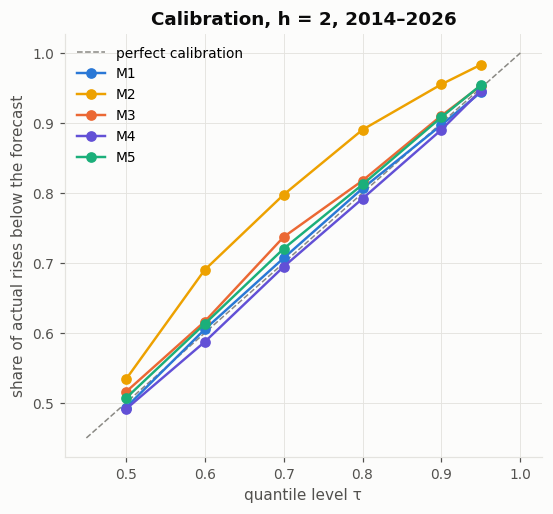

In [8]:
fig, ax = plt.subplots(figsize=(5.6, 5))
ax.plot([0.45, 1], [0.45, 1], color="#8a8984", lw=1, ls="--", label="perfect calibration")
for m in ["M1", "M2", "M3", "M4", "M5"]:
    g = e2[e2.model == m]
    ax.plot(g.tau, g.coverage, marker="o", ms=6, color=MODEL_COLORS[m], label=m, lw=1.6)
ax.set_xlabel("quantile level τ"); ax.set_ylabel("share of actual rises below the forecast")
ax.set_title("Calibration, h = 2, 2014–2026"); ax.legend(loc="upper left")
save(fig, "05_calibration.png"); plt.show()

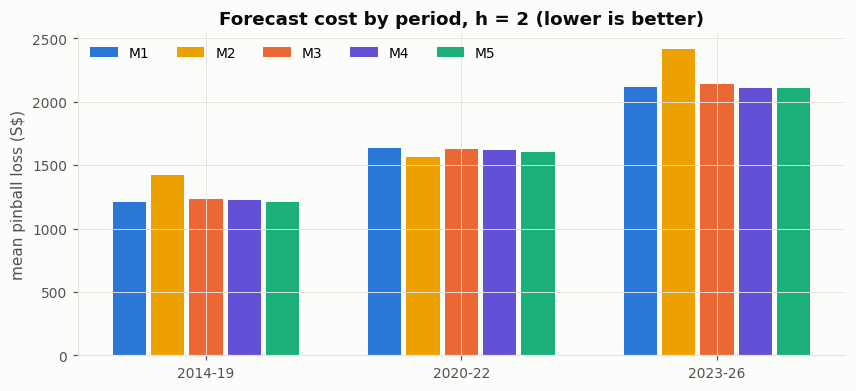

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
models = ["M1", "M2", "M3", "M4", "M5"]; periods = list(PERIODS); w = 0.15
for i, m in enumerate(models):
    vals = [pp.loc[m, p] for p in periods]
    ax.bar(np.arange(len(periods)) + (i - 2) * w, vals, width=w - 0.02, color=MODEL_COLORS[m], label=m)
ax.set_xticks(range(len(periods)), periods); ax.set_ylabel("mean pinball loss (S$)")
ax.set_title("Forecast cost by period, h = 2 (lower is better)"); ax.legend(ncol=5, loc="upper left")
save(fig, "05_pinball_by_period.png"); plt.show()

## Fan chart: Cat B, best model, 2022–2026

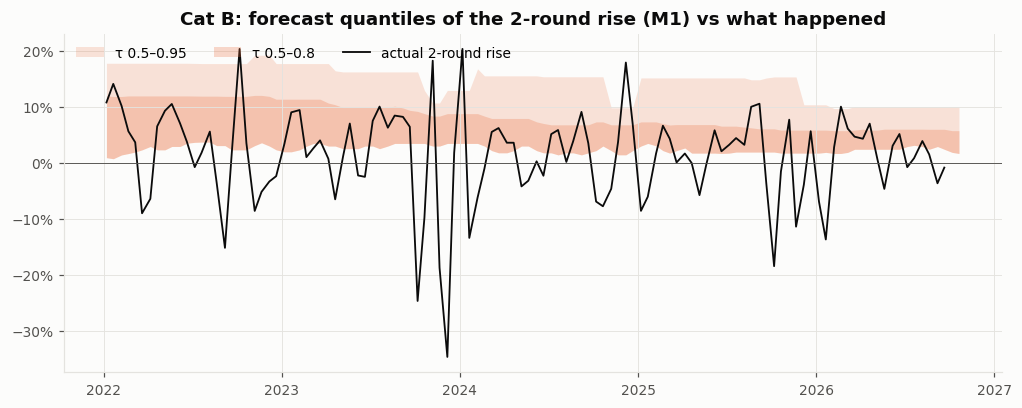

In [10]:
g = fc[(fc.model == best) & (fc.h == H) & (fc.category == "B") & (fc.month >= "2022-01")]
w = g.pivot_table(index=["month", "bidding_no"], columns="tau", values="q_pct").reset_index()
act = g[g.tau == 0.5].set_index(["month", "bidding_no"]).actual_pct.reindex(pd.MultiIndex.from_frame(w[["month", "bidding_no"]]))
x = pd.to_datetime(w.month) + pd.to_timedelta(np.where(w.bidding_no == 1, 6, 20), unit="D")
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(x, w[0.5], w[0.95], color=CAT_COLORS["B"], alpha=0.18, lw=0, label="τ 0.5–0.95")
ax.fill_between(x, w[0.5], w[0.8], color=CAT_COLORS["B"], alpha=0.25, lw=0, label="τ 0.5–0.8")
ax.plot(x, act.values, color="#0b0b0b", lw=1.2, label="actual 2-round rise")
ax.axhline(0, color="#52514e", lw=0.6)
from matplotlib.ticker import PercentFormatter
ax.yaxis.set_major_formatter(PercentFormatter(1, 0))
ax.set_title(f"Cat B: forecast quantiles of the 2-round rise ({best}) vs what happened"); ax.legend(loc="upper left", ncol=3)
save(fig, "05_fan_catB.png"); plt.show()